# Results and Analysis

In [1]:
import numpy as np
import os
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.metrics import cohen_kappa_score
import torch
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset, TensorDataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.metrics import classification_report, balanced_accuracy_score, cohen_kappa_score
from collections import Counter
warnings.filterwarnings('ignore')

In [ ]:
x_train = torch.load('/data/x_train.pt')
y_train = torch.load('/data/y_train.pt')
x_test = torch.load('/data/x_test.pt')
y_test = torch.load('/data/y_test.pt')

train_dataset = TensorDataset(x_train, y_train)
test_dataset = TensorDataset(x_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Load Trained Models

In [ ]:
# Traditional CNN

class CNN(nn.Module):
    def __init__(self, num_classes=5):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.3)

        # After 3 pooling: 224 -> 112 -> 56 -> 28
        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.fc2 = nn.Linear(256, num_classes)
        
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        
        return x

cnn_model = CNN(num_classes=5).to(device)
cnn_model.load_state_dict(torch.load('/models/cnn_state_dict.pth', map_location=device))

<All keys matched successfully>

In [ ]:
# EfficientNet

def create_efficientnet(num_classes=5, dropout_rate=0.3, verbose=False):
    model = models.efficientnet_b3(pretrained=True)
    
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(dropout_rate),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(dropout_rate),
        nn.Linear(512, num_classes)
    )
    return model

efficientnet_model = create_efficientnet(num_classes=5, dropout_rate=0.3)
efficientnet_model.to(device)
efficientnet_model.load_state_dict(torch.load('/models/efficientnet_state_dict.pth', map_location=device))

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth
100%|██████████| 47.2M/47.2M [00:00<00:00, 174MB/s]


<All keys matched successfully>

In [ ]:
# ResNet

def create_resnet(num_classes=5, dropout_rate=0.5, verbose=False):
    model = models.resnet50(pretrained=True)
    
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(dropout_rate),
        nn.Linear(in_features, 512),
        nn.ReLU(),
        nn.Dropout(dropout_rate/2),
        nn.Linear(512, num_classes)
    )
    return model

resnet_model = create_resnet(num_classes=5, dropout_rate=0.5)
resnet_model.to(device)
resnet_model.load_state_dict(torch.load('/models/resnet_state_dict.pth', map_location=device))

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 161MB/s]


<All keys matched successfully>

## Performance Analysis

In [7]:
class_names = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
models = {
  'CNN': cnn_model,
  'EfficientNet-B3': efficientnet_model,
  'ResNet-50': resnet_model
}

results = {}
for model_name, model in models.items():
  model.eval()
  all_preds = []
  all_true = []
  
  with torch.no_grad():
      for images, labels in test_loader:
          images, labels = images.to(device), labels.to(device)
          outputs = model(images)
          preds = torch.argmax(outputs, dim=1)
          
          all_preds.extend(preds.cpu().numpy())
          all_true.extend(labels.cpu().numpy())
  
  balanced_acc = balanced_accuracy_score(all_true, all_preds)
  qwk = cohen_kappa_score(all_true, all_preds, weights='quadratic')
  
  results[model_name] = {
      'predictions': all_preds,
      'true_labels': all_true,
      'balanced_accuracy': balanced_acc,
      'quadratic_weighted_kappa': qwk
  }

### Overall Performance

In [8]:
def create_performance_summary(results):
  summary_data = []
  for model_name, metrics in results.items():
      summary_data.append({
          'Model': model_name,
          'Balanced Accuracy': round(metrics['balanced_accuracy'], 4),
          'Quadratic Weighted Kappa': round(metrics['quadratic_weighted_kappa'], 4),
          'Error Rate': round(1 - metrics['balanced_accuracy'], 4)
      })
  return pd.DataFrame(summary_data)

### Class-Wise Performance

In [9]:
def create_classwise_summary(results, class_names=['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']):
   f1_data = {class_name: {} for class_name in class_names}
   
   for model_name, metrics in results.items():
       y_true = metrics['true_labels']
       y_pred = metrics['predictions']
       
       # Get F1-scores
       report = classification_report(y_true, y_pred, 
                                    target_names=class_names,
                                    output_dict=True,
                                    zero_division=0)
       
       for class_name in class_names:
           f1_data[class_name][model_name] = round(report[class_name]['f1-score'], 4)
   
   df = pd.DataFrame(f1_data).T  # Transpose to get classes as rows
   return df

### Failure Analysis

In [10]:
def create_failure_analysis(results):
  failure_data = []
  
  for model_name, metrics in results.items():
      y_true = np.array(metrics['true_labels'])
      y_pred = np.array(metrics['predictions'])

      total_errors = np.sum(y_true != y_pred)
      error_rate = total_errors / len(y_true)
      
      misclass_patterns = []
      for i in range(len(y_true)):
          if y_true[i] != y_pred[i]:
              misclass_patterns.append((y_true[i], y_pred[i]))
      
      pattern_counts = Counter(misclass_patterns)
      most_common = pattern_counts.most_common(3)
      
      # Adjacent vs distant errors
      adjacent_errors = sum(1 for true, pred in misclass_patterns if abs(pred - true) == 1)
      distant_errors = sum(1 for true, pred in misclass_patterns if abs(pred - true) > 1)
      
      # Critical misses (severe cases predicted as less severe)
      critical_misses = sum(1 for true, pred in misclass_patterns if true >= 3 and pred < true)
      
      failure_data.append({
          'Model': model_name,
          'Total Errors': total_errors,
          'Error Rate': round(error_rate, 4),
          'Adjacent Errors': adjacent_errors,
          'Distant Errors': distant_errors,
          'Critical Misses': critical_misses
      })
  
  return pd.DataFrame(failure_data)

In [11]:
# Generate all summaries
performance_df = create_performance_summary(results)
classwise_df = create_classwise_summary(results)
failure_df = create_failure_analysis(results)

# Save as markdown files
with open('performance_table.md', 'w') as f:
   f.write(performance_df.to_markdown(index=False))

with open('classwise_table.md', 'w') as f:
   f.write(classwise_df.to_markdown())

with open('failure_table.md', 'w') as f:
   f.write(failure_df.to_markdown(index=False))

# Display results
print("OVERALL PERFORMANCE SUMMARY")
print("=" * 50)
display(performance_df)

print("\nCLASS-WISE PERFORMANCE (F1-Score Pivot)")
print("=" * 50)
display(classwise_df)

print("\nFAILURE CASE ANALYSIS")
print("=" * 50)
display(failure_df)

print("\nMarkdown files saved:")
print("- outputs/performance_table.md")
print("- outputs/classwise_table.md") 
print("- outputs/failure_table.md")

OVERALL PERFORMANCE SUMMARY


,Model,Balanced Accuracy,Quadratic Weighted Kappa,Error Rate
0,CNN,0.4973,0.7233,0.5027
1,EfficientNet-B3,0.6300,0.8490,0.3700
2,ResNet-50,0.5624,0.8107,0.4376



CLASS-WISE PERFORMANCE (F1-Score Pivot)


,CNN,EfficientNet-B3,ResNet-50
No DR,0.9301,0.9652,0.9551
Mild,0.3504,0.5868,0.5634
Moderate,0.6869,0.7700,0.7650
Severe,0.3143,0.3385,0.3846
Proliferative,0.2529,0.4870,0.1299



FAILURE CASE ANALYSIS


,Model,Total Errors,Error Rate,Adjacent Errors,Distant Errors,Critical Misses
0,CNN,194,0.2647,101,93,73
1,EfficientNet-B3,144,0.1965,97,47,45
2,ResNet-50,156,0.2128,97,59,73



Markdown files saved:
- outputs/performance_table.md
- outputs/classwise_table.md
- outputs/failure_table.md


## Explainability and Feature Analysis

In [12]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 84.8 MB/s eta 0:00:00:00:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 1.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 19.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 3.2 MB/s eta 0:00:0000:01m00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 2.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 26.3 MB/s eta 0:00:00:00:0100:01


In [13]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [14]:
def show_gradcam(model, model_name, images, true_labels, device, target_layers, figsize=(15, 12), save_dir='/kaggle/working/gradcam_images'):
   """
   Generate and save GradCAM visualizations for a model
   
   Args:
       model: The trained model
       model_name: Name of the model (for saving files)
       images: Input images tensor
       true_labels: True labels tensor
       device: Device to run on
       target_layers: Layers for GradCAM
       figsize: Figure size
       save_dir: Directory to save images
   """
   # Create directory if it doesn't exist
   os.makedirs(save_dir, exist_ok=True)
   
   model.eval()
   cam = GradCAM(model=model, target_layers=target_layers)
   
   # Find one correctly predicted example for each class (0-4)
   class_indices = {}
   for i, label in enumerate(true_labels):
       class_val = label.item()
       
       # Skip if we already found an example for this class
       if class_val in class_indices or class_val not in [0, 1, 2, 3, 4]:
           continue
           
       # Check if this example is correctly predicted
       input_tensor = images[i:i+1].to(device)
       with torch.no_grad():
           pred_class = torch.argmax(model(input_tensor)).item()
       
       # Only use this example if prediction matches true label
       if pred_class == class_val:
           class_indices[class_val] = i
   
   sorted_classes = sorted(class_indices.keys())
   num_classes = len(sorted_classes)
   
   if num_classes == 0:
       print(f"No correctly predicted examples found for {model_name}")
       return
   
   fig, axes = plt.subplots(num_classes, 3, figsize=figsize)
   if num_classes == 1:
       axes = axes.reshape(1, -1)
   
   for row, class_num in enumerate(sorted_classes):
       i = class_indices[class_num]
       input_tensor = images[i:i+1].to(device)
       
       true_class = true_labels[i].item()
       target = [ClassifierOutputTarget(true_class)]
       
       with torch.no_grad():
           pred_class = torch.argmax(model(input_tensor)).item()
       
       grayscale_cam = cam(input_tensor=input_tensor, targets=target)
       
       image_np = images[i].permute(1, 2, 0).cpu().numpy()
       image_np = np.clip(image_np, 0, 1)
       visualization = show_cam_on_image(image_np, grayscale_cam[0], use_rgb=True)
       
       axes[row, 0].imshow(image_np)
       axes[row, 0].set_title(f'True: {true_class}, Pred: {pred_class}')
       axes[row, 0].axis('off')
       
       axes[row, 1].imshow(grayscale_cam[0], cmap='jet')
       axes[row, 1].set_title('GradCAM (True Class)')
       axes[row, 1].axis('off')
       
       axes[row, 2].imshow(visualization)
       axes[row, 2].set_title('Overlay')
       axes[row, 2].axis('off')
   
   # Add model name to the title
   plt.suptitle(f'{model_name} GradCAM Analysis', fontsize=16, y=0.98)
   
   # Save the figure
   filename = f'{model_name.lower().replace("-", "_").replace(" ", "_")}_gradcam.png'
   filepath = os.path.join(save_dir, filename)
   plt.savefig(filepath, dpi=150, bbox_inches='tight')
   print(f"✓ Saved: {filepath}")
   
   # Show missing classes info
   found_classes = set(sorted_classes)
   missing_classes = set([0, 1, 2, 3, 4]) - found_classes
   print(f"Found correctly predicted examples for classes: {sorted(found_classes)}")
   if missing_classes:
       print(f"No correctly predicted examples found for classes: {sorted(missing_classes)}")
   
   plt.tight_layout()
   plt.show()
   plt.close()  # Close to free memory

### CNN

✓ Saved: /kaggle/working/gradcam_images/cnn_gradcam.png
Found correctly predicted examples for classes: [0, 1, 2, 3, 4]


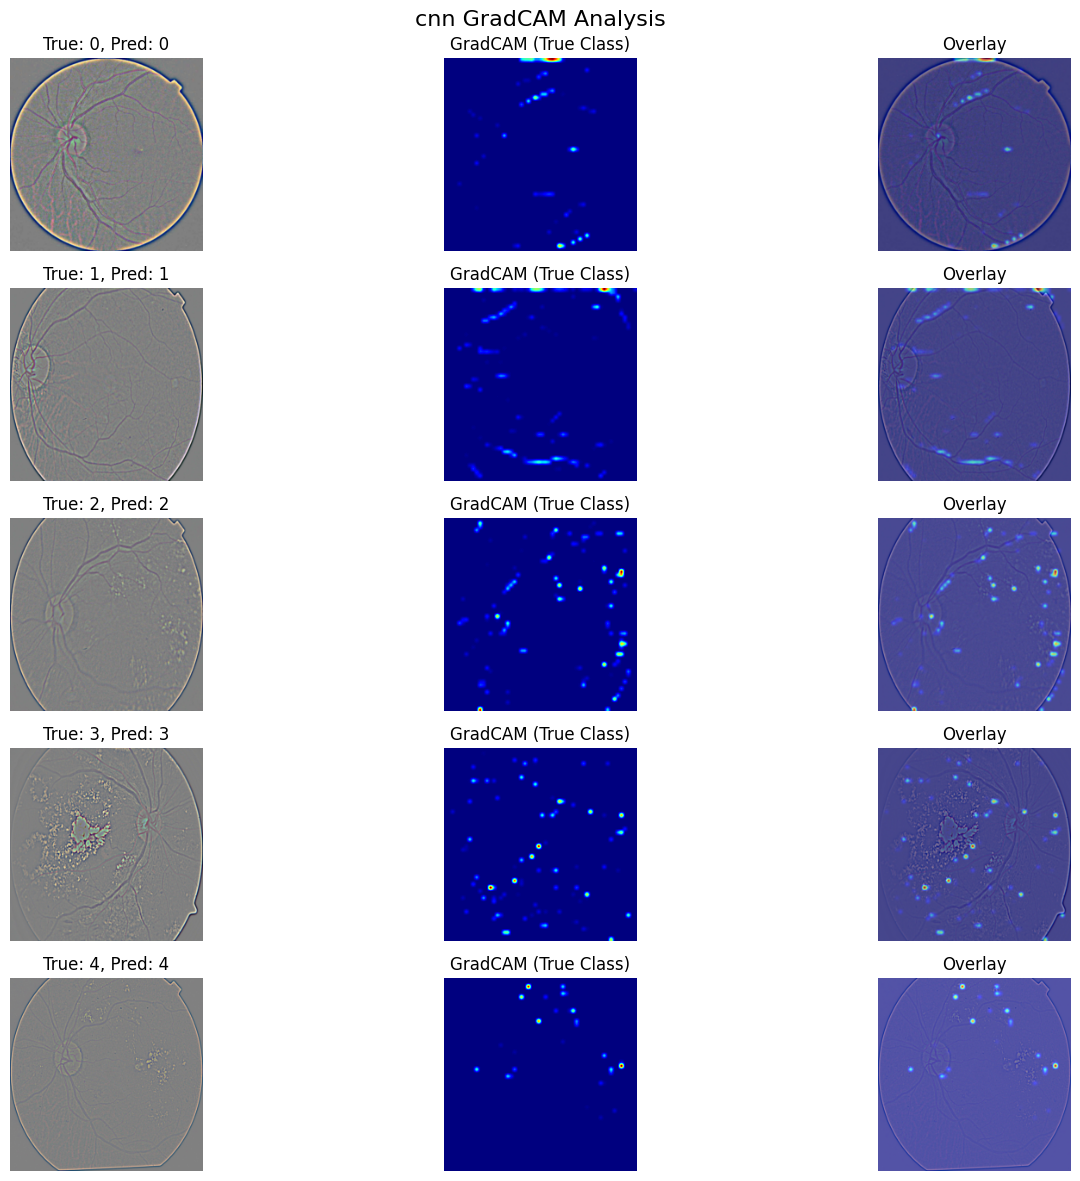

In [15]:
target_layers = [cnn_model.conv3]
cams = show_gradcam(cnn_model, 'cnn', x_train, y_train, device, target_layers)

### EfficientNet

✓ Saved: /kaggle/working/gradcam_images/efficientnet_gradcam.png
Found correctly predicted examples for classes: [0, 1, 2, 3, 4]


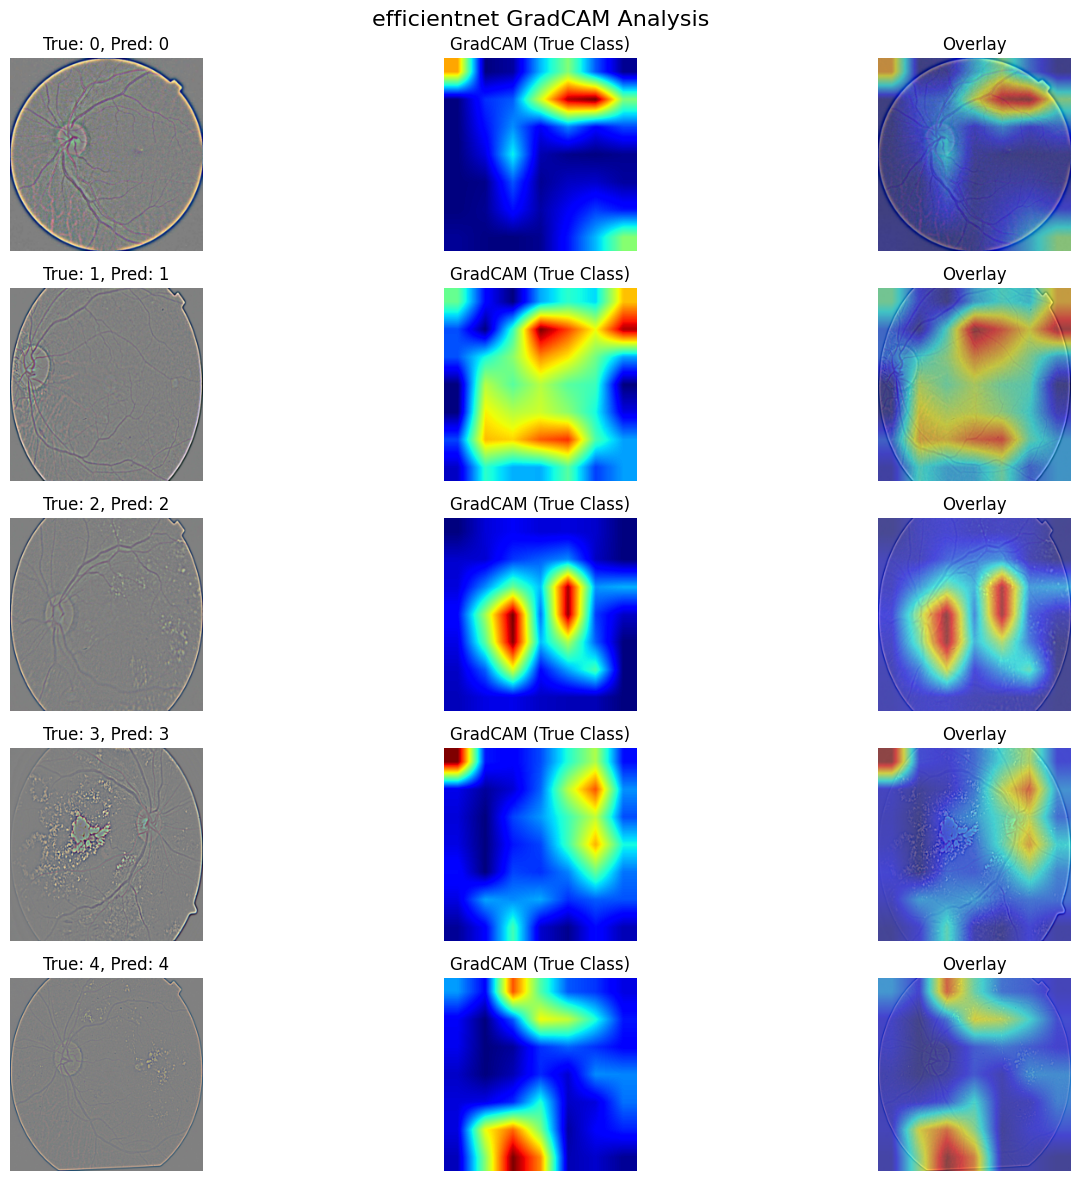

In [16]:
target_layers = [efficientnet_model.features[-1]]
cams = show_gradcam(efficientnet_model, 'efficientnet', x_train, y_train, device, target_layers)

### ResNet

✓ Saved: /kaggle/working/gradcam_images/resnet_gradcam.png
Found correctly predicted examples for classes: [0, 1, 2, 3, 4]


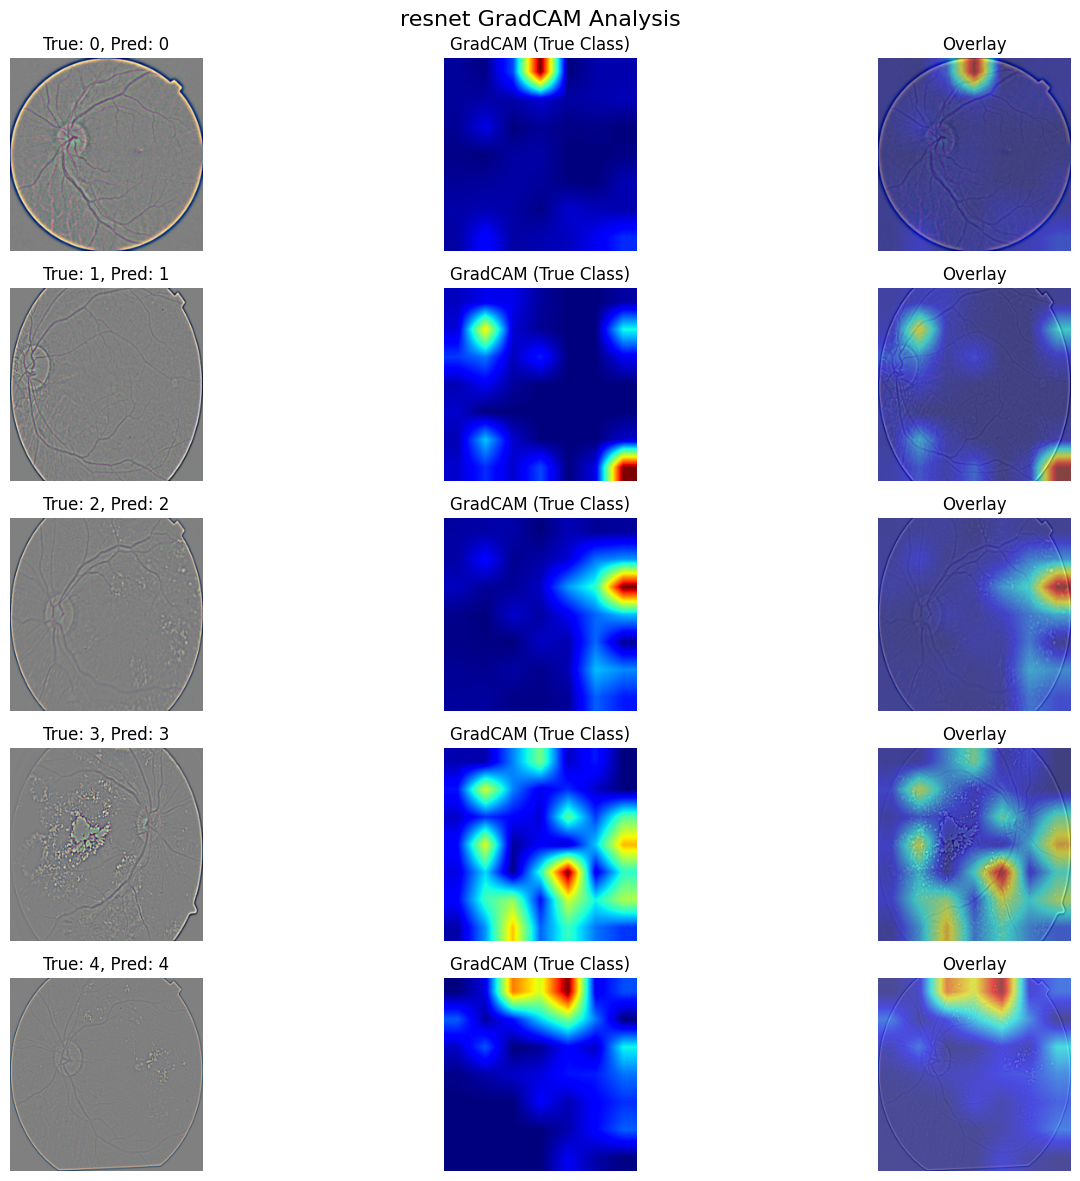

In [17]:
target_layers = [resnet_model.layer4[-1]]
cams = show_gradcam(resnet_model, 'resnet', x_train, y_train, device, target_layers)